
# 🏠 Bengaluru House Price Prediction

### Data Cleaning, Exploratory Data Analysis, Feature Engineering and Machine Learning

**Target Role:** Fresher Data Scientist / ML Engineer  
**Dataset:** Bengaluru House Price Dataset (13,320 Records)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn  
**Environment:** Jupyter Notebook

---

## 📌 Project Overview

This project focuses on predicting residential property prices in Bengaluru using Machine Learning.

The dataset contains property-related information such as location, total square footage, number of bedrooms (BHK), bathrooms, balconies, and property price.

The main objective is to clean the raw data, explore important patterns, prepare useful features, and build Machine Learning regression models to estimate house prices in Indian Rupees (₹ Lakhs).

## 🎯 Project Objectives

1. Understand the dataset and identify missing values and duplicate records.
2. Clean inconsistent data and convert property area values into numeric square feet.
3. Perform Exploratory Data Analysis (EDA) to understand property prices and features.
4. Create useful features such as BHK and square feet per bedroom.
5. Identify and handle unusual property records using domain knowledge.
6. Prepare categorical and numerical features for Machine Learning.
7. Train and compare Linear Regression, Ridge Regression, Lasso Regression, and Decision Tree models.
8. Evaluate model performance using MAE, RMSE, and R² score.

## 🛠️ Key Challenges

1. **Data Cleaning:** Handling missing values, duplicate records, and inconsistent data formats.
2. **Area Conversion:** Converting area ranges and different measurement units into numeric square feet.
3. **Outlier Analysis:** Identifying unrealistic property areas, BHK combinations, and price values.
4. **Location Handling:** Preparing location data for Machine Learning.
5. **Data Leakage Prevention:** Keeping `price_per_sqft`, which is calculated using the target price, out of the model input features.

## 📊 Expected Project Outcomes

- Cleaned and prepared dataset.
- Exploratory Data Analysis with visualizations.
- Feature engineering and outlier analysis.
- Comparison of multiple regression models.
- Model evaluation and house price predictions.
- Final project conclusion.




## Section 1: Importing Core Libraries

We import the required Python libraries for data analysis and machine learning.

- **Pandas:** Used for loading, cleaning, and analyzing datasets.
- **NumPy:** Used for numerical calculations.
- **Matplotlib and Seaborn:** Used for creating graphs and visualizations.
- **Scikit-Learn:** Used for splitting data, building regression models, and evaluating model performance.
- **Warnings:** Used to control unnecessary warning messages.


In [29]:

# Import core libraries

import pandas as pd
import numpy as np

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Machine Learning libraries
from sklearn.model_selection import train_test_split

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Model evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All required libraries imported successfully!")



All required libraries imported successfully!


## Section 2: Data Ingestion & Feature Understanding

In this section, we load the Bengaluru House Price dataset and understand its columns, data types, and missing values.

### Feature Dictionary (Data Schema)

| Column Name | Data Type | Description | Role in Project |
|---|---|---|---|
| `area_type` | Categorical | Type of property area (Super built-up, Plot area, Built-up area) | Categorical Feature |
| `availability` | Categorical | Property availability status or possession date | To be reviewed during feature selection |
| `location` | Categorical | Geographical area or locality in Bengaluru | Important Categorical Feature |
| `size` | Text | Bedroom information (e.g., 2 BHK, 4 Bedroom) | Used to extract BHK |
| `society` | Text | Name of the residential society or apartment | High Missing Values |
| `total_sqft` | Text / Mixed | Total property area, sometimes containing ranges or different units | Main Numerical Feature after cleaning |
| `bath` | Numerical | Number of bathrooms | Numerical Feature |
| `balcony` | Numerical | Number of balconies | Numerical Feature |
| `price` | Numerical | Property price in ₹ Lakhs | Target Variable (y) |

### Key Observations from Initial Data Audit

- The dataset contains **13,320 rows and 9 columns**.
- The `society` column has approximately **41.3% missing values**. We will review whether it is useful before deciding to remove it.
- The `location` column has approximately **0.01% missing values**.
- The `size` column has approximately **0.12% missing values**.
- The `bath` column has approximately **0.55% missing values**.
- The `balcony` column has approximately **4.57% missing values**.

We will handle missing values during the data-cleaning stage. Rows with missing `location` or `size` values will be removed, while missing `bath` and `balcony` values will be filled using their median values.


In [30]:
# Load the raw dataset

df = pd.read_csv("Bengaluru_House_Data.csv")

# Display dataset dimensions
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

# Display first 5 records
df.head()


Dataset Dimensions: 13320 rows, 9 columns


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [31]:
# Check column names, data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 1.6 MB


In [32]:
# Check missing values in each column

missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        (df.isnull().sum() / len(df)) * 100
    ).round(2)
})

# Sort columns by missing percentage
missing_df = missing_df.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

missing_df


,Missing Count,Missing Percentage (%)
society,5502,41.31
balcony,609,4.57
bath,73,0.55
size,16,0.12
location,1,0.01
area_type,0,0.00
availability,0,0.00
total_sqft,0,0.00
price,0,0.00


### Key Observations (Data Audit)

- The dataset contains **13,320 rows and 9 columns**.
- The `society` column has approximately **41.3% missing values**. Since a large number of values are missing, we will review its usefulness before deciding to remove this column.
- The `location` (0.01%) and `size` (0.12%) columns have very few missing values. We will remove rows where these important values are missing.
- The `bath` (0.55%) and `balcony` (4.57%) columns contain missing numerical values. We will fill these missing values using the median.

These decisions will be applied during the data-cleaning stage.


## Section 3: Exploratory Data Analysis (EDA) – Visualizing Market Trends

Exploratory Data Analysis (EDA) helps us understand the dataset through statistical summaries and visualizations.

In this section, we will:
1. Analyze the distribution of house prices.
2. Identify unusually high and low property prices.
3. Explore the locations with the highest number of property listings.

These visualizations will help us understand the housing market before data cleaning and model building.
EDA helps uncover underlying distributions, patterns, and anomalies in the housing data.


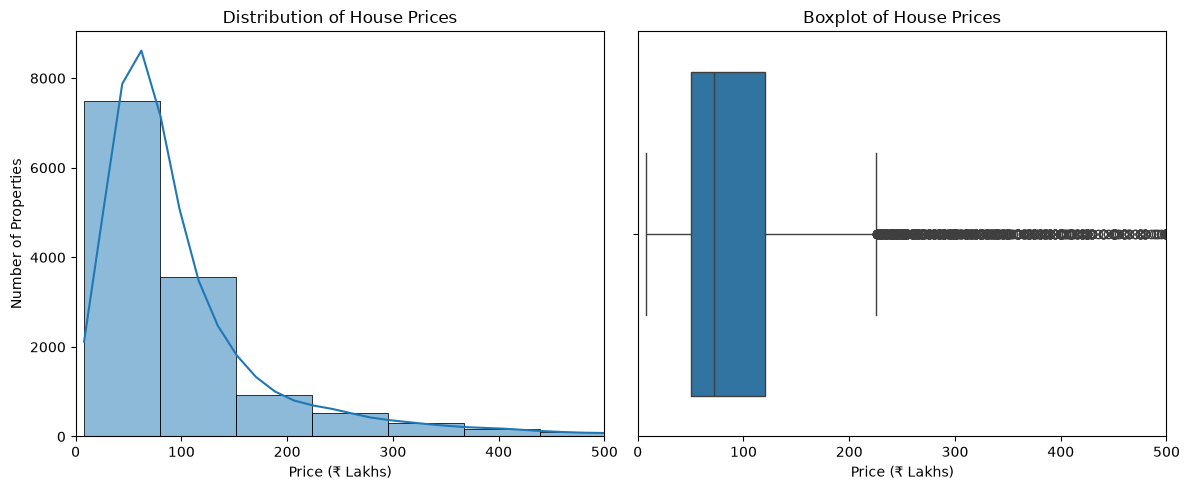

In [33]:
# Figure 1: Distribution of House Prices

plt.figure(figsize=(12, 5))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(
    df["price"].dropna(),
    bins=50,
    kde=True
)
plt.title("Distribution of House Prices")
plt.xlabel("Price (₹ Lakhs)")
plt.ylabel("Number of Properties")
plt.xlim(0, 500)

# Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=df["price"].dropna())
plt.title("Boxplot of House Prices")
plt.xlabel("Price (₹ Lakhs)")
plt.xlim(0, 500)

plt.tight_layout()
plt.show()


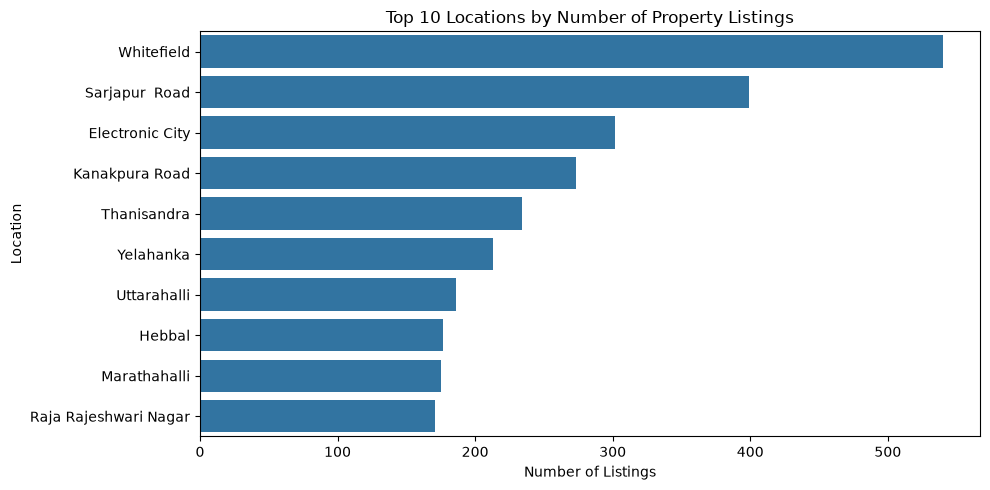

In [34]:
# Figure 2: Top 10 Locations by Number of Listings

top_10_locations = (
    df["location"]
    .dropna()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_10_locations.values,
    y=top_10_locations.index
)

plt.title("Top 10 Locations by Number of Property Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Location")

plt.tight_layout()
plt.show()


### Key EDA Takeaways

1. **Price Distribution:** The histogram helps us understand how property prices are distributed. The boxplot helps identify unusually high and low price values.
2. **Price Variation:** Property prices vary across the dataset, indicating differences in property values.
3. **Location Analysis:** The top 10 locations show where the dataset contains the highest number of property listings.

**Note:** These observations are based on the raw dataset. Further analysis will be performed after data cleaning.

## Section 4: Data Cleaning & Preprocessing

Real-world datasets often contain missing values, duplicate records, inconsistent formats, and invalid entries. In this section, we prepare the raw Bengaluru house price dataset for analysis and machine learning.

### Data Cleaning Steps

1. **Remove Unnecessary Columns:** Remove `society` because it contains a large number of missing values. Remove `availability` because it will not be used in our current model.
2. **Handle Missing Values:** Remove rows with missing `location` or `size`. Fill missing `bath` and `balcony` values using their median.
3. **Feature Extraction:** Extract the number of bedrooms from the `size` column and create a numerical feature called `bhk`.
4. **Standardize Property Area:** Convert area ranges and different measurement units in `total_sqft` into numerical square feet.
5. **Remove Invalid Records:** Identify and remove records where important property measurements cannot be converted.

In [35]:
# Step 1: Remove unnecessary columns

df_clean = df.drop(columns=["society", "availability"])

# Step 2: Handle missing values

# Remove rows with missing location or size
df_clean = df_clean.dropna(subset=["location", "size"]).copy()

# Fill missing numerical values using median
df_clean["bath"] = df_clean["bath"].fillna(
    df_clean["bath"].median()
)

df_clean["balcony"] = df_clean["balcony"].fillna(
    df_clean["balcony"].median()
)

print("Dataset shape after handling missing values:")
print(df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Dataset shape after handling missing values:
(13303, 7)

Remaining missing values:
area_type     0
location      0
size          0
total_sqft    0
bath          0
balcony       0
price         0
dtype: int64


In [36]:
# Step 3: Extract BHK from the size column

df_clean["bhk"] = (
    df_clean["size"]
    .str.extract(r"(\d+)")
    .astype(float)
)

print("Sample after BHK extraction:")

df_clean[["size", "bhk"]].head(10)


Sample after BHK extraction:


,size,bhk
0,2 BHK,2.0
1,4 Bedroom,4.0
2,3 BHK,3.0
3,3 BHK,3.0
4,2 BHK,2.0
5,2 BHK,2.0
6,4 BHK,4.0
7,4 BHK,4.0
8,3 BHK,3.0
9,6 Bedroom,6.0


In [37]:
# Step 4: Convert total_sqft into numerical square feet

def convert_sqft_to_num(value):

    try:
        value = str(value).strip()

        # Handle area ranges such as 2100 - 2850
        if "-" in value:
            parts = value.split("-")

            if len(parts) == 2:
                return (
                    float(parts[0].strip()) +
                    float(parts[1].strip())
                ) / 2

        # Handle different measurement units
        unit_conversions = {
            "sq.meter": 10.7639,
            "sq.meters": 10.7639,
            "sq.yards": 9,
            "sq.yard": 9,
            "acres": 43560,
            "acre": 43560,
            "cents": 435.6,
            "guntha": 1089,
            "perch": 272.25,
            "grounds": 2400
        }

        lower_value = value.lower()

        for unit, factor in unit_conversions.items():
            if unit in lower_value:
                number = float(
                    lower_value.replace(unit, "").strip()
                )
                return number * factor

        # Handle normal numerical values
        return float(value)

    except (ValueError, TypeError):
        return np.nan


# Apply conversion
df_clean["total_sqft_clean"] = (
    df_clean["total_sqft"].apply(convert_sqft_to_num)
)

# Count records that could not be converted
unconverted_count = df_clean["total_sqft_clean"].isna().sum()

print("Unconverted records:", unconverted_count)

# Remove records with invalid area values
df_clean = df_clean.dropna(
    subset=["total_sqft_clean"]
).copy()

print("\nDataset shape after area conversion:")
print(df_clean.shape)

df_clean[["total_sqft", "total_sqft_clean"]].head(10)

Unconverted records: 32

Dataset shape after area conversion:
(13271, 9)


,total_sqft,total_sqft_clean
0,1056,1056.0
1,2600,2600.0
2,1440,1440.0
3,1521,1521.0
4,1200,1200.0
5,1170,1170.0
6,2732,2732.0
7,3300,3300.0
8,1310,1310.0
9,1020,1020.0


## Section 5: Feature Engineering & Location Preparation

Feature engineering means creating useful features from existing columns.

### Price per square foot (EDA only)
We calculate price per square foot for analysis and outlier investigation. It is derived from `price`, so it MUST NOT be used as a model input.

### High-cardinality location
The raw dataset contains many locality names. We keep the cleaned location text in this stage. Rare-category handling is performed inside the training pipeline with `OneHotEncoder(min_frequency=11, handle_unknown='ignore')`. This is important: category frequencies are learned from training folds only, rather than from the complete dataset before splitting.


In [38]:
# Step 1: Calculate price per square foot

df_clean["price_per_sqft"] = (
    df_clean["price"] * 100000 /
    df_clean["total_sqft_clean"]
)

# Remove extra spaces from location names
df_clean["location"] = (
    df_clean["location"].str.strip()
)

print("Price per square foot created successfully!")

df_clean[
    ["location", "total_sqft_clean", "price", "price_per_sqft"]
].head()

Price per square foot created successfully!


,location,total_sqft_clean,price,price_per_sqft
0,Electronic City Phase II,1056.0,39.07,3699.810606
1,Chikka Tirupathi,2600.0,120.00,4615.384615
2,Uttarahalli,1440.0,62.00,4305.555556
3,Lingadheeranahalli,1521.0,95.00,6245.890861
4,Kothanur,1200.0,51.00,4250.000000


In [39]:
# Inspect location frequency; do not group categories using the full dataset.
location_stats = df_clean['location'].value_counts()
print('Unique locations:', df_clean['location'].nunique())
print('Top 10 locations:')
display(location_stats.head(10))


Unique locations: 1292
Top 10 locations:


location
Whitefield               538
Sarjapur  Road           397
Electronic City          304
Kanakpura Road           273
Thanisandra              236
Yelahanka                212
Uttarahalli              186
Hebbal                   177
Marathahalli             175
Raja Rajeshwari Nagar    171
Name: count, dtype: int64

In [40]:
# Keep original locality names here. Rare-category grouping is learned
# inside OneHotEncoder during model fitting, using training data only.
df_clean['location'] = df_clean['location'].astype(str).str.strip()
print('Locations retained for train/test split:', df_clean['location'].nunique())


Locations retained for train/test split: 1292


## Section 6: Domain-Driven Outlier Detection & Removal

Outliers are observations that are unusually high or low compared to the general data distribution.

In real estate data, unusual values may occur because of incorrect measurements, data-entry mistakes, or properties with uncommon characteristics.

We will apply two domain-based filters:

1. **Square Feet Per BHK:** Identify properties with unusually low area per bedroom.
2. **Bathroom Count:** Identify properties with unusually high bathroom counts compared to their BHK.

These filters are practical data-cleaning rules. They are not universal rules for every property, so we will inspect the records and document the number of observations removed at each stage.

**Methodology Note:** We avoid applying target-derived price-per-square-foot and BHK pricing filters before the train/test split. This helps prevent data leakage and supports a more reliable model evaluation.




In [41]:
# Filter 1: Calculate square feet per BHK

df_clean["sqft_per_bhk"] = (
    df_clean["total_sqft_clean"] / df_clean["bhk"]
)

print(
    "Records before sqft per BHK filter:",
    len(df_clean)
)

# Keep properties with at least 300 sqft per BHK
df_step1 = df_clean[
    df_clean["sqft_per_bhk"] >= 300
].copy()

print(
    "Records after sqft per BHK filter:",
    len(df_step1)
)

print(
    "Records removed:",
    len(df_clean) - len(df_step1)
)



Records before sqft per BHK filter: 13271
Records after sqft per BHK filter: 12526
Records removed: 745


### Outlier Filter 2: Bathroom Count Anomaly
Properties having significantly more bathrooms than total bedrooms (e.g., a 2 BHK apartment with 5 bathrooms) represent data anomalies.
Domain threshold: $\text{bath} < \text{bhk} + 2$.


In [42]:
df_step4 = df_step1[
    df_step1["bath"] < df_step1["bhk"] + 2
].copy()

print("Records after bathroom filter:", len(df_step4))
print("Records removed:", len(df_step1) - len(df_step4))

print("\nFinal cleaned dataset dimensions:")
print(df_step4.shape)


Records after bathroom filter: 12373
Records removed: 153

Final cleaned dataset dimensions:
(12373, 11)


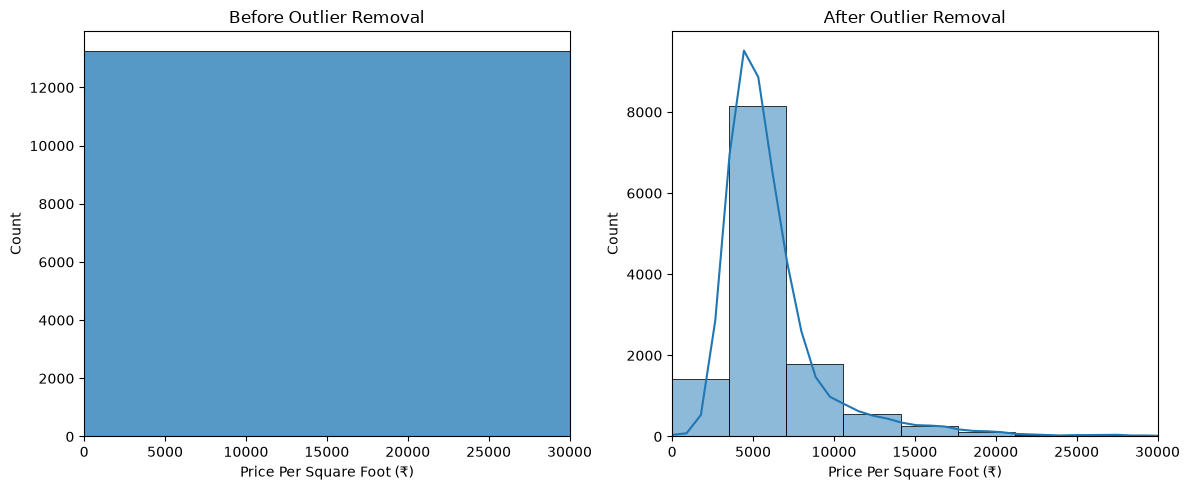

In [43]:
# Compare price per sqft before and after outlier removal

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(
    df_clean["price_per_sqft"],
    bins=50
)
plt.title("Before Outlier Removal")
plt.xlabel("Price Per Square Foot (₹)")
plt.xlim(0, 30000)

plt.subplot(1, 2, 2)
sns.histplot(
    df_step4["price_per_sqft"],
    bins=50,
    kde=True
)
plt.title("After Outlier Removal")
plt.xlabel("Price Per Square Foot (₹)")
plt.xlim(0, 30000)

plt.tight_layout()
plt.show()


---
## Section 7: Preprocessing Pipeline & Data Leakage Prevention

### 1. Defining Independent Features ($X$) and Target ($y$)
In professional data science, we must strictly prevent **Data Leakage**:
- **Target Variable ($y$):** Property price in ₹ Lakhs (`price`).
- **Predictor Features ($X$):** `total_sqft`, `bath`, `bhk`, and `location`.
- **Preventing Target Leakage:** We strictly drop `price_per_sqft` because it was derived using the target column (`price * 100000 / total_sqft`). Using it as an input would allow the model to cheat during training and fail in production.

### 2. Scikit-Learn `ColumnTransformer` & `Pipeline`
Rather than applying `pd.get_dummies()` manually to the whole dataset (which causes data leakage between train and test sets), we implement a Scikit-Learn **Pipeline**:
1. **Numerical Features (`total_sqft`, `bath`, `bhk`):** Passed through directly to preserve interpretability.
2. **Categorical Feature (`location`):** Encoded using `OneHotEncoder(drop='first', min_frequency=11, handle_unknown='ignore')`.
3. **Consistent Transformations:** The pipeline fits strictly on training data and transforms test or future production inputs using the exact same learned vocabulary and column ordering.


In [44]:
# The cleaned dataset from previous sections uses 'total_sqft_clean' column
# We rename it to 'total_sqft_num' for clarity
df_step4 = df_step4.copy()
df_step4['total_sqft_num'] = df_step4['total_sqft_clean']

feature_cols = ['total_sqft_num', 'bath', 'bhk', 'location']
X = df_step4[feature_cols].copy()
y = df_step4['price'].copy()

print("Features selected for modeling:", X.columns.tolist())
print(f"Feature Matrix Shape: {X.shape}")
print(f"Target Vector Shape:  {y.shape}")
print("\nFirst 5 rows of feature matrix:")
X.head()




Features selected for modeling: ['total_sqft_num', 'bath', 'bhk', 'location']
Feature Matrix Shape: (12373, 4)
Target Vector Shape:  (12373,)

First 5 rows of feature matrix:


,total_sqft_num,bath,bhk,location
0,1056.0,2.0,2.0,Electronic City Phase II
1,2600.0,5.0,4.0,Chikka Tirupathi
2,1440.0,2.0,3.0,Uttarahalli
3,1521.0,3.0,3.0,Lingadheeranahalli
4,1200.0,2.0,2.0,Kothanur


---
## Section 8: Train/Test Split & Baseline Benchmark

### 1. Partitioning Data (80% Train, 20% Test)
We divide the dataset into two subsets using `random_state=42` for reproducibility:
- **Training Set (80%):** Used for fitting preprocessing parameters and cross-validating models.
- **Testing Set (20%):** Kept completely untouched during training to serve as a final evaluation of real-world generalization.

### 2. Baseline Benchmark (`DummyRegressor`)
In production machine learning, a model's performance is meaningless without a naive baseline benchmark.
We establish a **Mean Predictor Baseline** (`DummyRegressor(strategy='mean')`). Any viable regression algorithm must beat this baseline by significantly reducing Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) and achieving a positive $R^2$ score.


In [45]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Extract and sort unique training locations for validation
known_locations = sorted(X_train['location'].unique().tolist())

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples:  {X_test.shape[0]}")
print(f"Unique Localities in Training Set: {len(known_locations)}")

# Baseline Benchmark: Predicts training mean for all samples
dummy_baseline = DummyRegressor(strategy='mean')
dummy_baseline.fit(X_train, y_train)
y_dummy_pred = dummy_baseline.predict(X_test)

baseline_r2 = r2_score(y_test, y_dummy_pred)
baseline_mae = mean_absolute_error(y_test, y_dummy_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_dummy_pred))

print("\n--- Naive Baseline Performance (Dummy Mean Predictor) ---")
print(f"Baseline R² Score: {baseline_r2:.4f} (Benchmark: ~0.0)")
print(f"Baseline MAE:     ₹{baseline_mae:.2f} Lakhs")
print(f"Baseline RMSE:    ₹{baseline_rmse:.2f} Lakhs")



Training Samples: 9898
Testing Samples:  2475
Unique Localities in Training Set: 1104

--- Naive Baseline Performance (Dummy Mean Predictor) ---
Baseline R² Score: -0.0001 (Benchmark: ~0.0)
Baseline MAE:     ₹70.34 Lakhs
Baseline RMSE:    ₹140.32 Lakhs


---
## Section 9: Model Selection with 5-Fold Cross-Validation on Training Data

To determine the best algorithm, we compare four diverse regression techniques:
1. **Multiple Linear Regression:** The standard linear baseline with OLS parameters.
2. **Ridge Regression ($L_2$ Regularization):** Shrinks coefficients to mitigate multicollinearity between neighboring localities.
3. **Lasso Regression ($L_1$ Regularization):** Performs automatic feature selection by driving non-informative coefficients to zero.
4. **Decision Tree Regressor:** A non-linear tree-based regressor capable of capturing localized threshold splits.

> [!IMPORTANT]
> **Zero Test Leakage:** Model selection and hyperparameter tuning are conducted strictly on `X_train` using 5-Fold Cross-Validation (`KFold`). The test set (`X_test`) remains untouched.


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor

# 1. Construct Preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', ['total_sqft_num', 'bath', 'bhk']),
        ('cat', OneHotEncoder(drop='first', min_frequency=11, handle_unknown='ignore'), ['location'])
    ]
)

# 2. Setup 5-Fold Cross-Validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Define Algorithms & Hyperparameter Search Spaces
candidate_models = {
    'Linear Regression': {
        'model': Pipeline([('prep', preprocessor), ('reg', LinearRegression())]),
        'params': {'reg__fit_intercept': [True, False]}
    },
    'Ridge Regression': {
        'model': Pipeline([('prep', preprocessor), ('reg', Ridge())]),
        'params': {'reg__alpha': [0.01, 0.1, 1.0, 5.0, 10.0]}
    },
    'Lasso Regression': {
        'model': Pipeline([('prep', preprocessor), ('reg', Lasso(max_iter=10000))]),
        'params': {'reg__alpha': [0.001, 0.01, 0.1, 1.0]}
    },
    'Decision Tree': {
        'model': Pipeline([('prep', preprocessor), ('reg', DecisionTreeRegressor(random_state=42))]),
        'params': {'reg__max_depth': [6, 8, 12, None], 'reg__min_samples_split': [2, 5, 10]}
    }
}

# 4. Execute GridSearchCV on Training Data
cv_summary = []

for name, config in candidate_models.items():
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=kfold,
        scoring='r2',
        n_jobs=1
    )
    grid.fit(X_train, y_train)
    cv_summary.append({
        'Model': name,
        'Best CV R² Score (Train)': round(grid.best_score_, 4),
        'Best Hyperparameters': grid.best_params_,
        'Best Estimator': grid.best_estimator_
    })

cv_df = pd.DataFrame(cv_summary).sort_values(by='Best CV R² Score (Train)', ascending=False).reset_index(drop=True)
cv_df[['Model', 'Best CV R² Score (Train)', 'Best Hyperparameters']]



,Model,Best CV R² Score (Train),Best Hyperparameters
0,Decision Tree,0.5201,"{'reg__max_depth': 12, 'reg__min_samples_split..."
1,Lasso Regression,0.3107,{'reg__alpha': 0.001}
2,Linear Regression,0.2845,{'reg__fit_intercept': True}
3,Ridge Regression,0.2723,{'reg__alpha': 10.0}


---
## Section 10: Model Evaluation on Untouched Test Data

Now that each algorithm has been tuned on the training data, we evaluate each model on the **untouched test set (`X_test`)**.

We report three standard regression metrics:
- **$R^2$ Score (Coefficient of Determination):** Proportion of price variance explained by the model (higher is better, max 1.0).
- **Mean Absolute Error (MAE):** Average error magnitude in ₹ Lakhs (lower is better).
- **Root Mean Squared Error (RMSE):** Error penalized for large deviations in ₹ Lakhs (lower is better).


In [47]:
# Evaluate each tuned model on the untouched test set
eval_results = []

# Include baseline for benchmark comparison
eval_results.append({
    'Model': 'Baseline (Dummy Mean)',
    'CV R² (Train)': 0.0000,
    'Test R²': round(baseline_r2, 4),
    'Test MAE (₹ Lakhs)': round(baseline_mae, 2),
    'Test RMSE (₹ Lakhs)': round(baseline_rmse, 2)
})

for row in cv_summary:
    est = row['Best Estimator']
    y_test_pred = est.predict(X_test)
    
    eval_results.append({
        'Model': row['Model'],
        'CV R² (Train)': row['Best CV R² Score (Train)'],
        'Test R²': round(r2_score(y_test, y_test_pred), 4),
        'Test MAE (₹ Lakhs)': round(mean_absolute_error(y_test, y_test_pred), 2),
        'Test RMSE (₹ Lakhs)': round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)
    })

# Construct Clean Model Performance Comparison Table
performance_table = pd.DataFrame(eval_results)
performance_table = performance_table.sort_values(by='Test R²', ascending=False).reset_index(drop=True)

print("📊 Comprehensive Model Performance Comparison Table:")
performance_table


📊 Comprehensive Model Performance Comparison Table:


,Model,CV R² (Train),Test R²,Test MAE (₹ Lakhs),Test RMSE (₹ Lakhs)
0,Decision Tree,0.5201,0.5056,35.21,98.66
1,Lasso Regression,0.3107,0.2842,51.12,118.71
2,Linear Regression,0.2845,0.2383,53.45,122.46
3,Ridge Regression,0.2723,0.2201,54.04,123.91
4,Baseline (Dummy Mean),0.0000,-0.0001,70.34,140.32


In [48]:
# Select the winning model using TRAINING cross-validation only.
# Do not choose a model by looking at test-set scores.
best_cv_row = max(cv_summary, key=lambda row: row['Best CV R² Score (Train)'])
best_model_name = best_cv_row['Model']
best_pipeline = best_cv_row['Best Estimator']

# Retrieve the already-computed, one-time test evaluation for the CV winner.
winning_test_row = performance_table.loc[
    performance_table['Model'] == best_model_name
].iloc[0]
best_test_r2 = float(winning_test_row['Test R²'])
best_test_mae = float(winning_test_row['Test MAE (₹ Lakhs)'])
best_test_rmse = float(winning_test_row['Test RMSE (₹ Lakhs)'])

print(f'Winning model selected by 5-fold CV: {best_model_name}')
print(f'Test R² (final holdout evaluation): {best_test_r2:.4f}')
print(f'Test MAE: ₹{best_test_mae:.2f} Lakhs')
print(f'Test RMSE: ₹{best_test_rmse:.2f} Lakhs')
print(f'MAE reduction vs baseline: {(baseline_mae-best_test_mae)/baseline_mae:.1%}')

Winning model selected by 5-fold CV: Decision Tree
Test R² (final holdout evaluation): 0.5056
Test MAE: ₹35.21 Lakhs
Test RMSE: ₹98.66 Lakhs
MAE reduction vs baseline: 49.9%


---
## Section 11: Visual Evaluation & Residual Diagnostics

We inspect residuals (`actual - predicted`) to understand where the model makes errors. These plots help reveal systematic patterns and large errors. Because the selected model may be a Decision Tree, we do not claim that linear-regression assumptions must hold.

1. **Actual vs Predicted:** points closer to the diagonal indicate more accurate predictions.
2. **Residuals vs Predicted:** visible patterns may indicate systematic errors or changing error spread.
3. **Residual Distribution:** shows whether errors are centered near zero and whether large errors are common.


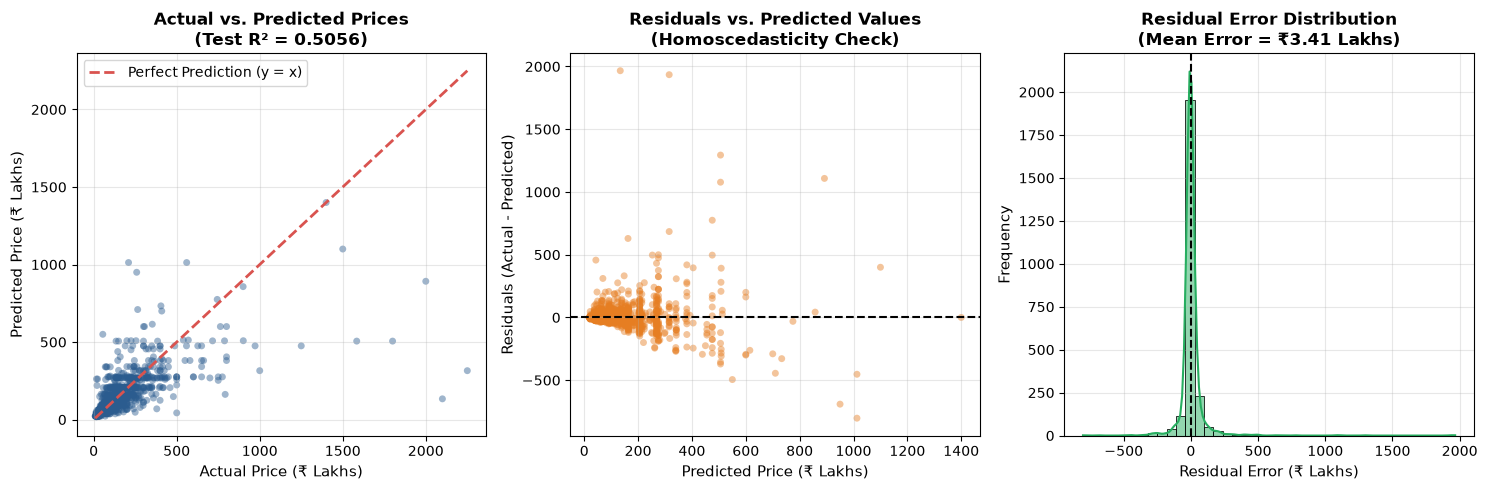

In [49]:
# Compute predictions and residuals using best model
y_pred_best = best_pipeline.predict(X_test)
residuals = y_test - y_pred_best

plt.figure(figsize=(15, 5))

# Plot 1: Actual vs Predicted
plt.subplot(1, 3, 1)
plt.scatter(y_test, y_pred_best, alpha=0.45, color='#2b5c8f', edgecolors='none', s=25)
lo = min(y_test.min(), y_pred_best.min())
hi = max(y_test.max(), y_pred_best.max())
plt.plot([lo, hi], [lo, hi], color='#d9534f', linestyle='--', linewidth=2, label='Perfect Prediction (y = x)')
plt.title(f'Actual vs. Predicted Prices\n(Test R² = {best_test_r2:.4f})', fontsize=12, fontweight='bold')
plt.xlabel('Actual Price (₹ Lakhs)', fontsize=11)
plt.ylabel('Predicted Price (₹ Lakhs)', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)

# Plot 2: Residuals vs Predicted
plt.subplot(1, 3, 2)
plt.scatter(y_pred_best, residuals, alpha=0.45, color='#e67e22', edgecolors='none', s=25)
plt.axhline(0, color='black', linestyle='--', linewidth=1.5)
plt.title('Residuals vs. Predicted Values\n(Homoscedasticity Check)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Price (₹ Lakhs)', fontsize=11)
plt.ylabel('Residuals (Actual - Predicted)', fontsize=11)
plt.grid(True, alpha=0.3)

# Plot 3: Residual Distribution
plt.subplot(1, 3, 3)
sns.histplot(residuals, bins=40, kde=True, color='#27ae60')
plt.axvline(0, color='black', linestyle='--', linewidth=1.5)
plt.title(f'Residual Error Distribution\n(Mean Error = ₹{residuals.mean():.2f} Lakhs)', fontsize=12, fontweight='bold')
plt.xlabel('Residual Error (₹ Lakhs)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## Section 12: Understanding Which Features Matter

The interpretation method depends on the selected algorithm:
- For Linear Regression / Ridge / Lasso, coefficients show the direction and size of a feature's relationship with predicted price (interpret location coefficients relative to the dropped reference category).
- For Decision Tree, use feature importance as a relative measure of how much each transformed feature helps reduce impurity. It is not a causal effect and should not be described as a price increase per unit.


In [50]:
# Interpret the selected model safely, regardless of its algorithm.
reg_step = best_pipeline.named_steps['reg']
prep_step = best_pipeline.named_steps['prep']
feature_names_out = prep_step.get_feature_names_out()

if hasattr(reg_step, 'feature_importances_'):
    importance = pd.Series(reg_step.feature_importances_, index=feature_names_out)
    print('Top 15 Decision Tree feature importances:')
    display(importance.sort_values(ascending=False).head(15).to_frame('importance'))
elif hasattr(reg_step, 'coef_'):
    coefficients = np.ravel(reg_step.coef_)
    coef_series = pd.Series(coefficients, index=feature_names_out)
    print('Intercept:', float(np.asarray(reg_step.intercept_).ravel()[0]) if np.ndim(reg_step.intercept_) else float(reg_step.intercept_))
    print('Top positive coefficients:')
    display(coef_series.sort_values(ascending=False).head(10).to_frame('coefficient'))
    print('Top negative coefficients:')
    display(coef_series.sort_values().head(10).to_frame('coefficient'))
else:
    print('This estimator does not expose coefficients or feature importances.')


Top 15 Decision Tree feature importances:


,importance
num__total_sqft_num,0.860616
num__bath,0.036003
cat__location_infrequent_sklearn,0.024187
num__bhk,0.019917
cat__location_Malleshwaram,0.008352
cat__location_Rajaji Nagar,0.008237
cat__location_Indira Nagar,0.007833
cat__location_Chamrajpet,0.004198
cat__location_Whitefield,0.004144
cat__location_Koramangala,0.003490


---
## Section 13: Prediction Function & Input Validation

The function builds a DataFrame with the exact feature names expected by the fitted pipeline. `OneHotEncoder(handle_unknown='ignore')` allows an unseen locality to be processed without crashing; however, an unseen locality receives no learned locality-specific adjustment. This is NOT necessarily the Bengaluru city average, so predictions for unknown locations should be treated cautiously.


In [51]:
def predict_price(location, sqft, bath, bhk):
    """Estimate a Bengaluru property price in ₹ Lakhs."""
    if not isinstance(location, str) or not location.strip():
        raise ValueError('Please provide a non-empty location name.')
    if sqft is None or float(sqft) <= 0:
        raise ValueError('Square footage must be greater than zero.')
    if bath is None or int(bath) <= 0:
        raise ValueError('Bathrooms must be a positive integer.')
    if bhk is None or int(bhk) <= 0:
        raise ValueError('BHK must be a positive integer.')

    input_df = pd.DataFrame([{
        'total_sqft_num': float(sqft),
        'bath': int(bath),
        'bhk': int(bhk),
        'location': location.strip()
    }])
    prediction = best_pipeline.predict(input_df)[0]
    if location.strip() not in set(X_train['location']):
        print('Warning: this locality was not present in training data; its location effect is unknown.')
    return round(float(prediction), 2)

print('Prediction function is ready.')


Prediction function is ready.


In [52]:
# Test several normal inputs and one unseen locality.
print('House-price prediction examples (₹ Lakhs):')
examples = [
    ('Whitefield', 1200, 2, 2),
    ('Indira Nagar', 1800, 3, 3),
    ('1st Phase JP Nagar', 1000, 2, 2),
    ('Electronic City Phase II', 1050, 2, 2),
    ('NovelGreenValleyEstate', 1200, 2, 2)
]
for loc, sqft, bath, bhk in examples:
    price = predict_price(loc, sqft, bath, bhk)
    print(f'{loc}: ₹{price:.2f} Lakhs')


House-price prediction examples (₹ Lakhs):
Whitefield: ₹65.06 Lakhs
Indira Nagar: ₹111.34 Lakhs
1st Phase JP Nagar: ₹47.35 Lakhs
Electronic City Phase II: ₹47.35 Lakhs
NovelGreenValleyEstate: ₹65.06 Lakhs


In [53]:
# Test Invalid Input Handling
try:
    predict_price('Whitefield', -500, 2, 2)
except ValueError as e:
    print("✅ Input Validation Test 1 Passed (Negative Sqft caught):", e)

try:
    predict_price('Whitefield', 1200, 0, 2)
except ValueError as e:
    print("✅ Input Validation Test 2 Passed (Zero Bath caught):", e)


✅ Input Validation Test 1 Passed (Negative Sqft caught): Square footage must be greater than zero.
✅ Input Validation Test 2 Passed (Zero Bath caught): Bathrooms must be a positive integer.


---
## Section 14: Saving the Trained Model

Save the complete fitted scikit-learn pipeline so inference uses the same preprocessing and model. Joblib is sufficient here; a second file with a `.pkl` extension created by `joblib.dump` is redundant and may confuse users.


In [54]:
import joblib
import json

joblib_filename = 'bengaluru_house_price_model.joblib'
joblib.dump(best_pipeline, joblib_filename)

metadata = {
    'model_name': best_model_name,
    'input_features': feature_cols,
    'metrics': {
        'baseline_mae_lakhs': float(baseline_mae),
        'test_r2': float(best_test_r2),
        'test_mae_lakhs': float(best_test_mae),
        'test_rmse_lakhs': float(best_test_rmse)
    },
    'note': 'Metrics are valid for this fixed train/test split and this notebook run.'
}
with open('model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print(f'Saved model: {joblib_filename}')
print('Saved model_metadata.json')


Saved model: bengaluru_house_price_model.joblib
Saved model_metadata.json


In [55]:
# Verification: Load the saved model and test prediction

loaded_model = joblib.load('bengaluru_house_price_model.joblib')

test_sample = pd.DataFrame([{
    'total_sqft_num': 1200.0,
    'bath': 2,
    'bhk': 2,
    'location': 'Whitefield'
}])

loaded_pred = loaded_model.predict(test_sample)[0]

print(f"Prediction from Loaded Model: ₹{loaded_pred:.2f} Lakhs")

print("Saved Model Loaded and Prediction Successful!")

Prediction from Loaded Model: ₹65.06 Lakhs
Saved Model Loaded and Prediction Successful!


---
## Section 15: Fresher Interview Guide (Top 10 Technical Questions & Answers)

### Q1. What was the machine learning problem and target variable in this project?
**Answer:** The objective was to predict residential property prices in Bengaluru in ₹ Lakhs. Because the target variable (`price`) is a continuous numerical value predicted from property attributes (`total_sqft`, `bath`, `bhk`, `location`), this is a Supervised Machine Learning Regression problem.

### Q2. How did you structure your preprocessing to avoid Data Leakage?
**Answer:** I avoided manual one-hot encoding on the full dataset before splitting. Instead, I split the data first (80% train / 20% test) and built a Scikit-Learn `ColumnTransformer` inside a `Pipeline`. Preprocessing parameters (such as location categories and any numerical transformations) were learned strictly on training data and consistently applied to test and inference inputs. Furthermore, I strictly removed `price_per_sqft` because it was derived directly from the target variable (`price`).

### Q3. How did you handle the high-cardinality location feature?
**Answer:** The raw dataset had over 1,300 unique locations, many with only 1 or 2 listings. One-hot encoding all of them would create excessive dimensionality and cause overfitting. I computed listing frequencies and used `OneHotEncoder(min_frequency=11, handle_unknown='ignore')` inside the training pipeline so rare categories are grouped using training-fold data only.

### Q4. How does your `predict_price` function handle an unseen or misspelled location?
**Answer:** In my inference pipeline, if an input locality was not present in training data, `OneHotEncoder(handle_unknown='ignore')` allows prediction to continue. The model has no learned locality-specific effect for that unseen value, so the result should be treated cautiously.

### Q5. How did you handle domain-specific outliers?

**Answer:** I applied a 2-step domain-driven outlier removal process:

1. **Minimum Sqft/BHK Ratio:** Removed properties where square footage per bedroom was under 300 sqft.
2. **Bathroom Anomaly Filter:** Removed properties where the number of bathrooms was unusually high compared to the number of bedrooms (`bath < bhk + 2`).

These filters helped remove unusual property records using real-estate domain knowledge.

### Q6. Why did you use a Baseline Model (Dummy Regressor)?

**Answer:** I used a Dummy Regressor with the mean strategy as a baseline to evaluate how well my machine learning models perform compared to a simple model. It predicts the average house price for every property. The baseline achieved an R² score of -0.0001 and an MAE of ₹70.34 Lakhs. My selected Decision Tree model performed better than the baseline, showing that it learned useful patterns from the dataset.


### Q7. How did you select the winning model?
**Answer:** I compared Linear Regression, Ridge, Lasso, and Decision Tree using 5-fold cross-validation on the training data. I selected the model with the highest mean CV R² score, then reported its performance on the untouched test set. The final winning model and metrics are generated when the notebook is run.

### Q8. What is Residual Analysis, and why is it important?
**Answer:** A residual is the difference between actual and predicted price (`actual - predicted`). Residual plots help identify systematic prediction errors, unusual observations, and changes in error spread. They are diagnostic plots; they do not by themselves prove that errors are normally distributed or that a model is unbiased.

### Q9. Why did you save the model using Joblib instead of standard Pickle?
**Answer:** `joblib` is optimized for serializing large NumPy arrays and Scikit-Learn pipelines containing multiple transformer steps. Furthermore, serializing the entire `Pipeline` (both preprocessor and regressor) guarantees that raw inputs can be passed directly to `model.predict()` without requiring manual one-hot encoding code in production.

### Q10. What are the key limitations of this project and how would you enhance it?
**Answer:**
1. **Temporal Trends:** Real estate prices fluctuate over time; adding a transaction timestamp would capture market inflation.
2. **Amenities & Age:** Incorporating builder reputation, floor level, and society amenities (gym, swimming pool) would improve accuracy on luxury apartments.
3. **Ensemble Methods:** Exploring Gradient Boosting (e.g., XGBoost, LightGBM) while preserving pipeline encapsulation.



---
## Section 15: Resume-Ready Project Summary

Use the following bullet points only AFTER running the complete notebook and confirming the final metrics. Replace bracketed values with the actual output from your run.

### Resume bullet points
- Built a Bengaluru house-price prediction project using Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.
- Cleaned missing and inconsistent property records; converted area measurements into numeric square feet and created BHK-related features.
- Compared Linear Regression, Ridge, Lasso and Decision Tree models using 5-fold cross-validation on training data.
- Selected the model using cross-validation and evaluated it on a separate holdout test set; achieved a test R² of **0.5056** and MAE of **₹35.21 Lakhs**.
- Packaged preprocessing and the selected estimator in one Scikit-learn Pipeline and saved it with Joblib for consistent future predictions.

### 30-second interview explanation
"I built a machine-learning regression project to estimate residential property prices in Bengaluru. I cleaned the dataset, explored price and location patterns, converted property area into numeric square feet, and created a BHK feature. I compared four regression algorithms using cross-validation on the training data, selected the best model using CV, and evaluated it on a separate test set. I also created a prediction function and saved the complete preprocessing-and-model pipeline with Joblib."

**Important:** Run all cells from top to bottom after placing `Bengaluru_House_Data.csv` in the notebook's working folder. Do not use old saved outputs or old resume metrics; use only the fresh results from this run.
